# Tarea 6 — Física Computacional II
## Análisis de un catálogo estelar mediante clases

**Nombre:** Sofia Catalina Soto Ferrada
**RUT:** 22.261.514-3

In [19]:
# Importamos las bibliotecas que utilizaremos
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [20]:
class CatalogoEstelar:
    """
    Permite trabajar con un catálogo de estrellas y calcular sus propiedades físicas.
    """

    def __init__(self, datos):
        """
        Inicializa un catálogo estelar.

        Parameters
        ----------
        datos : str or pandas.DataFrame
            Archivo del catálogo o DataFrame con los datos.
        """
        if isinstance(datos, str):
            self.datos = self.cargar_npz(datos)
        else:
            self.datos = datos.copy()

        # Limpiamos los datos automáticamente al crear el catálogo
        self.limpiar_datos()

    def cargar_npz(self, archivo):
        """
        Carga los datos de un archivo .npz y los organiza en un DataFrame.

        Parameters
        ----------
        archivo : str
            Nombre del archivo .npz.

        Returns
        -------
        pandas.DataFrame
            Datos del catálogo estelar.
        """
        # Leemos los datos del archivo
        archivo_npz = np.load(archivo, allow_pickle=True)

        # Organizamos los arreglos en un DataFrame
        datos = pd.DataFrame({
            "nombre": archivo_npz["nombre"],
            "L_Lsol": archivo_npz["L_Lsol"],
            "d_pc": archivo_npz["d_pc"],
            "T_K": archivo_npz["T_K"]
        })
        return datos

    def limpiar_datos(self):
        """
        Identifica valores faltantes e inválidos del catálogo.

        Returns
        -------
        None
        """
        # Contamos los valores originales que faltan
        faltantes = self.datos.isna().sum()
        porcentaje = (faltantes / len(self.datos)) * 100

        print("Valores faltantes antes de la limpieza:")
        print(pd.DataFrame({
            "Cantidad": faltantes,
            "Porcentaje (%)": porcentaje
        }))

        # Reemplazamos por NaN los valores físicos inválidos
        self.datos["L_Lsol"] = self.datos["L_Lsol"].where(self.datos["L_Lsol"] > 0)
        self.datos["d_pc"] = self.datos["d_pc"].where(self.datos["d_pc"] > 0)
        self.datos["T_K"] = self.datos["T_K"].where(self.datos["T_K"] > 0)

        print("\\nValores faltantes después de la limpieza:")
        print(self.datos.isna().sum())

    def calcular_flujo(self):
        """
        Calcula el flujo bolométrico recibido por cada estrella.

        Returns
        -------
        pandas.Series
            Flujo bolométrico en W m-2.
        """
        # Constantes para convertir luminosidad solar a W y pársecs a metros
        L_sol = 3.828e26
        pc_m = 3.085677581491367e16

        # Convertimos la luminosidad y la distancia a unidades del SI
        luminosidad = self.datos["L_Lsol"] * L_sol
        distancia = self.datos["d_pc"] * pc_m

        # Calculamos el flujo bolométrico
        flujo = luminosidad / (4 * np.pi * distancia**2)
        self.datos["Fbol"] = flujo
        return flujo

    def calcular_radio(self):
        """
        Calcula el radio estelar usando la ley de Stefan-Boltzmann.

        Returns
        -------
        pandas.Series
            Radio estelar en radios solares.
        """
        # Temperatura efectiva del Sol en kelvin
        T_sol = 5772

        # Calculamos el radio en unidades solares
        radio = np.sqrt(self.datos["L_Lsol"]) * (T_sol / self.datos["T_K"])**2
        self.datos["R_Rsol"] = radio
        return radio

    def calcular_magnitud(self):
        """
        Calcula la magnitud bolométrica absoluta.

        Returns
        -------
        pandas.Series
            Magnitud bolométrica absoluta.
        """
        # Calculamos la magnitud utilizando la luminosidad en unidades solares
        magnitud = 4.74 - 2.5 * np.log10(self.datos["L_Lsol"])
        self.datos["Mbol"] = magnitud
        return magnitud

    def calcular_lambda_max(self):
        """
        Calcula la longitud de onda de máxima emisión mediante la ley de Wien.

        Returns
        -------
        pandas.Series
            Longitud de onda máxima en nanómetros.
        """
        # Constante de desplazamiento de Wien en m K
        b = 2.8978e-3

        # Calculamos la longitud de onda y convertimos a nanómetros
        lambda_max = (b / self.datos["T_K"]) * 1e9
        self.datos["lambda_max_nm"] = lambda_max
        return lambda_max

    def clasificar_deteccion(self, umbral=1e-4):
        """
        Clasifica las estrellas según su flujo y el umbral de detección.

        Parameters
        ----------
        umbral : float, opcional
            Umbral de detección en W m-2. Por defecto es 1e-4.

        Returns
        -------
        pandas.Series
            Detectada, No detectada o Desconocida.
        """
        # Calculamos el flujo si todavía no está en el catálogo
        if "Fbol" not in self.datos.columns:
            self.calcular_flujo()

        # Comparamos el flujo con el umbral y conservamos los valores desconocidos
        deteccion = pd.Series("No detectada", index=self.datos.index, dtype="object")
        deteccion[self.datos["Fbol"] >= umbral] = "Detectada"
        deteccion[self.datos["Fbol"].isna()] = "Desconocida"

        self.datos["deteccion"] = deteccion
        return deteccion

    def estadisticas(self):
        """
        Calcula estadísticas de las propiedades numéricas del catálogo.

        Returns
        -------
        pandas.DataFrame
            Estadísticas descriptivas de las columnas numéricas.
        """
        # Seleccionamos las columnas numéricas
        columnas = self.datos.select_dtypes(include=[np.number]).columns
        
        # Calculamos las estadísticas solicitadas
        resumen = self.datos[columnas].describe(
            percentiles=[0.25, 0.50, 0.75]).loc[["mean", "50%", "std", "25%", "50%", "75%", "min", "max"]]
        
        resumen.index = [
            "Media", "Mediana", "Desviación estándar",
            "Percentil 25", "Percentil 50", "Percentil 75",
            "Mínimo", "Máximo"
        ]

        # Identificamos las estrellas con luminosidad, temperatura y radio extremos
        for columna in ["L_Lsol", "T_K", "R_Rsol"]:
            if columna in self.datos.columns:
                indice_min = self.datos[columna].idxmin()
                indice_max = self.datos[columna].idxmax()
                print("\\n", columna)
                print("Estrella con valor mínimo:", self.datos.loc[indice_min, "nombre"])
                print("Estrella con valor máximo:", self.datos.loc[indice_max, "nombre"])

        return resumen

    def resumen_por_temperatura(self, umbral=1e-4):
        """
        Agrupa las estrellas según su temperatura efectiva.

        Parameters
        ----------
        umbral : float, opcional
            Umbral de detección en W m-2. Por defecto es 1e-4.

        Returns
        -------
        pandas.DataFrame
            Estadísticas para cada grupo de temperatura.
        """
        # Calculamos el flujo si todavía no existe
        if "Fbol" not in self.datos.columns:
            self.calcular_flujo()

        # Creamos una columna numérica de detección; NaN no entra en el denominador
        self.datos["detectada_num"] = np.where(
            self.datos["Fbol"].notna(),
            (self.datos["Fbol"] >= umbral).astype(float),
            np.nan
        )

        # Definimos los intervalos y nombres de los grupos
        limites = [0, 5000, 7500, np.inf]
        grupos = ["Fría", "Intermedia", "Caliente"]

        # Asignamos cada estrella a un grupo según su temperatura
        self.datos["grupo_temperatura"] = pd.cut(
            self.datos["T_K"], bins=limites, labels=grupos, right=False
        )

        # Calculamos las estadísticas solicitadas para cada grupo
        resumen = self.datos.groupby(
            "grupo_temperatura", observed=False
        ).agg(
            n_estrellas=("T_K", "count"),
            temperatura_media=("T_K", "mean"),
            luminosidad_media=("L_Lsol", "mean"),
            flujo_mediano=("Fbol", "median"),
            fraccion_detectada=("detectada_num", "mean")
        )
        return resumen

    def graficar_hr(self):
        """
        Construye el diagrama de Hertzsprung-Russell.

        Returns
        -------
        None
        """
        # Seleccionamos estrellas con temperatura y luminosidad válidas
        datos = self.datos.dropna(subset=["T_K", "L_Lsol"])

        # Construimos el diagrama HR
        plt.figure(figsize=(8, 6))
        plt.scatter(datos["T_K"], datos["L_Lsol"], s=5)
        plt.yscale("log")
        plt.gca().invert_xaxis()
        plt.xlabel("Temperatura efectiva [K]")
        plt.ylabel("Luminosidad bolométrica [L_sol]")
        plt.title("Diagrama de Hertzsprung-Russell")
        plt.grid()
        plt.show()

    def graficar_histogramas(self, bins=30):
        """
        Construye histogramas de las propiedades del catálogo.

        Parameters
        ----------
        bins : int, opcional
            Número de intervalos de los histogramas. Por defecto es 30.

        Returns
        -------
        None
        """
        # Columnas y etiquetas de los histogramas
        columnas = ["L_Lsol", "d_pc", "T_K", "R_Rsol", "Mbol"]
        etiquetas = [
            "Luminosidad [L_sol]", "Distancia [pc]",
            "Temperatura efectiva [K]", "Radio [R_sol]",
            "Magnitud bolométrica absoluta"
        ]

        # Construimos un histograma para cada propiedad
        fig, axs = plt.subplots(3, 2, figsize=(12, 12))
        axs = axs.flatten()

        for i in range(len(columnas)):
            axs[i].hist(self.datos[columnas[i]].dropna(), bins=bins, edgecolor="black")
            axs[i].set_xlabel(etiquetas[i])
            axs[i].set_ylabel("Número de estrellas")
            axs[i].set_title(etiquetas[i])

        # Ocultamos el panel que no se utiliza
        axs[5].axis("off")
        plt.tight_layout()
        plt.show()

    def graficar_temperatura_flujo(self, umbral=1e-4):
        """
        Construye un histograma de temperaturas y un gráfico de flujo frente a distancia.

        Parameters
        ----------
        umbral : float, opcional
            Umbral de detección en W m-2. Por defecto es 1e-4.

        Returns
        -------
        None
        """
        # Calculamos el flujo si es necesario
        if "Fbol" not in self.datos.columns:
            self.calcular_flujo()

        # Seleccionamos datos válidos para cada gráfico
        datos_temp = self.datos.dropna(subset=["T_K"])
        datos_flujo = self.datos.dropna(subset=["d_pc", "Fbol", "T_K"])
        datos_flujo = datos_flujo[datos_flujo["Fbol"] > 0]

        # Creamos dos paneles
        fig, axs = plt.subplots(1, 2, figsize=(13, 5))

        # En el panel izquierdo, histograma de temperaturas
        axs[0].hist(datos_temp["T_K"], bins=30, edgecolor="black")
        axs[0].set_xlabel("Temperatura efectiva [K]")
        axs[0].set_ylabel("Número de estrellas")
        axs[0].set_title("Distribución de temperaturas")

        # En el panel derecho, flujo en función de la distancia
        puntos = axs[1].scatter(
            datos_flujo["d_pc"], datos_flujo["Fbol"],
            c=datos_flujo["T_K"], s=8
        )
        axs[1].set_yscale("log")
        axs[1].axhline(
            umbral, linestyle="--", color="black", label="Umbral de detección"
        )
        axs[1].set_xlabel("Distancia [pc]")
        axs[1].set_ylabel("Flujo bolométrico [W m$^{-2}$]")
        axs[1].set_title("Flujo en función de la distancia")
        axs[1].legend()
        fig.colorbar(puntos, ax=axs[1], label="Temperatura efectiva [K]")

        plt.tight_layout()
        plt.show()

    def graficar_grupos(self, umbral=1e-4):
        """
        Grafica la cantidad de estrellas y la fracción detectada por grupo.

        Parameters
        ----------
        umbral : float, opcional
            Umbral de detección en W m-2. Por defecto es 1e-4.

        Returns
        -------
        None
        """
        # Obtenemos el resumen por temperatura
        resumen = self.resumen_por_temperatura(umbral)

        # Creamos dos gráficos de barras
        fig, axs = plt.subplots(1, 2, figsize=(11, 5))

        axs[0].bar(resumen.index.astype(str), resumen["n_estrellas"])
        axs[0].set_xlabel("Grupo de temperatura")
        axs[0].set_ylabel("Número de estrellas")
        axs[0].set_title("Cantidad de estrellas por grupo")

        axs[1].bar(resumen.index.astype(str), resumen["fraccion_detectada"])
        axs[1].set_xlabel("Grupo de temperatura")
        axs[1].set_ylabel("Fracción detectada")
        axs[1].set_title("Fracción de detección por grupo")

        plt.tight_layout()
        plt.show()

    def guardar_resultados(self, archivo="catalogo_procesado.csv"):
        """
        Guarda el catálogo procesado en un archivo CSV.

        Parameters
        ----------
        archivo : str, opcional
            Nombre del archivo de salida.

        Returns
        -------
        None
        """
        # Exportamos el catálogo procesado a un archivo CSV
        self.datos.to_csv(archivo, index=False)
        print("Catálogo guardado en:", archivo)

    @classmethod
    def desde_dataframe(cls, datos):
        """
        Crea una instancia de CatalogoEstelar a partir de un DataFrame.

        Parameters
        ----------
        datos : pandas.DataFrame
            DataFrame con las columnas del catálogo.

        Returns
        -------
        CatalogoEstelar
            Nueva instancia de la clase.
        """
        # Creamos una nueva instancia utilizando el DataFrame recibido
        return cls(datos)

### Justificación de la limpieza de datos
Se conservaron los valores faltantes como NaN para evitar eliminar registros que todavía contienen información válida en otras columnas. Los valores no positivos de luminosidad, distancia y temperatura también se reemplazaron por NaN, ya que no corresponden a valores físicos válidos para estas propiedades.

In [22]:
# Cargamos el catálogo estelar original
catalogo = CatalogoEstelar("catalogo_100000_estrellas (1).npz")

# Mostramos los primeros cinco registros
catalogo.datos.head()

Valores faltantes antes de la limpieza:
        Cantidad  Porcentaje (%)
nombre         0           0.000
L_Lsol     10015          10.015
d_pc       10013          10.013
T_K         9972           9.972
\nValores faltantes después de la limpieza:
nombre        0
L_Lsol    14960
d_pc      15034
T_K       15006
dtype: int64


,nombre,L_Lsol,d_pc,T_K
0,Estrella_0000,77.418209,472.492956,5825.858426
1,Estrella_0001,43.943956,476.430023,5742.522518
2,Estrella_0002,NaN,291.203087,9076.064106
3,Estrella_0003,69.767066,162.889198,7043.306304
4,Estrella_0004,9.508317,382.695401,8319.621681


In [4]:
# Calculamos las propiedades físicas de las estrellas
catalogo.calcular_flujo()
catalogo.calcular_radio()
catalogo.calcular_magnitud()
catalogo.calcular_lambda_max()

# Mostramos los primeros cinco registros con los resultados
catalogo.datos.head()

,nombre,L_Lsol,d_pc,T_K,Fbol,R_Rsol,Mbol,lambda_max_nm
0,Estrella_0000,77.418209,472.492956,5825.858426,1.109465e-11,8.636830,0.017892,497.403093
1,Estrella_0001,43.943956,476.430023,5742.522518,6.193867e-12,6.697255,0.632752,504.621443
2,Estrella_0002,NaN,291.203087,9076.064106,NaN,NaN,NaN,319.279367
3,Estrella_0003,69.767066,162.889198,7043.306304,8.412535e-11,5.609507,0.130874,411.426094
4,Estrella_0004,9.508317,382.695401,8319.621681,2.077104e-12,1.484217,2.294741,348.309107


In [23]:
# Clasificamos las estrellas según el límite de detección
detecciones = catalogo.clasificar_deteccion()

# Contamos cuántas estrellas hay en cada clasificación
print(detecciones.value_counts(dropna=False))

No detectada    72265
Desconocida     27735
Name: count, dtype: int64


In [6]:
# Calculamos las estadísticas de las propiedades numéricas
estadisticas = catalogo.estadisticas()

# Mostramos la tabla de estadísticas
estadisticas

\n L_Lsol
Estrella con valor mínimo: Estrella_10217
Estrella con valor máximo: Estrella_45903
\n T_K
Estrella con valor mínimo: Estrella_5058
Estrella con valor máximo: Estrella_70445
\n R_Rsol
Estrella con valor mínimo: Estrella_62716
Estrella con valor máximo: Estrella_2395


,L_Lsol,d_pc,T_K,Fbol,R_Rsol,Mbol,lambda_max_nm
Media,50.113039,274.651935,6505.530747,6.350831e-11,7.396893,0.816928,497.712301
Mediana,50.262004,274.003200,6511.134245,1.904278e-11,5.059123,0.486900,445.053026
Desviación estándar,28.820631,129.876599,2016.436646,1.252768e-10,6.343032,1.061642,176.880626
Percentil 25,25.157857,161.842731,4755.441918,8.663404e-12,3.122172,0.051893,351.057824
Percentil 50,50.262004,274.003200,6511.134245,1.904278e-11,5.059123,0.486900,445.053026
Percentil 75,75.031325,386.932633,8254.480611,5.452607e-11,9.573955,1.238316,609.365029
Mínimo,0.101316,50.011610,3000.122706,1.470350e-14,0.112911,-0.259993,289.782774
Máximo,99.999374,499.999038,9999.904282,1.268404e-09,36.791630,7.225810,965.893826


In [24]:
# Agrupamos las estrellas según su temperatura
resumen_temperatura = catalogo.resumen_por_temperatura()

# Mostramos los resultados para cada grupo
resumen_temperatura

,n_estrellas,temperatura_media,luminosidad_media,flujo_mediano,fraccion_detectada
grupo_temperatura,,,,,
Fría,24139,4001.734479,49.993467,1.909984e-11,0.0
Intermedia,30397,6250.023700,50.236492,1.918179e-11,0.0
Caliente,30458,8744.869700,50.024197,1.883905e-11,0.0


In [18]:
# Repetimos el resumen utilizando un umbral menor
resumen_temperatura_2 = catalogo.resumen_por_temperatura(
    umbral=1e-12
)

# Mostramos los resultados para comparar ambos umbrales
resumen_temperatura_2

,n_estrellas,temperatura_media,luminosidad_media,flujo_mediano,fraccion_detectada
grupo_temperatura,,,,,
Fría,24139,4001.734479,49.993467,1.909984e-11,0.971425
Intermedia,30397,6250.023700,50.236492,1.918179e-11,0.974239
Caliente,30458,8744.869700,50.024197,1.883905e-11,0.970914


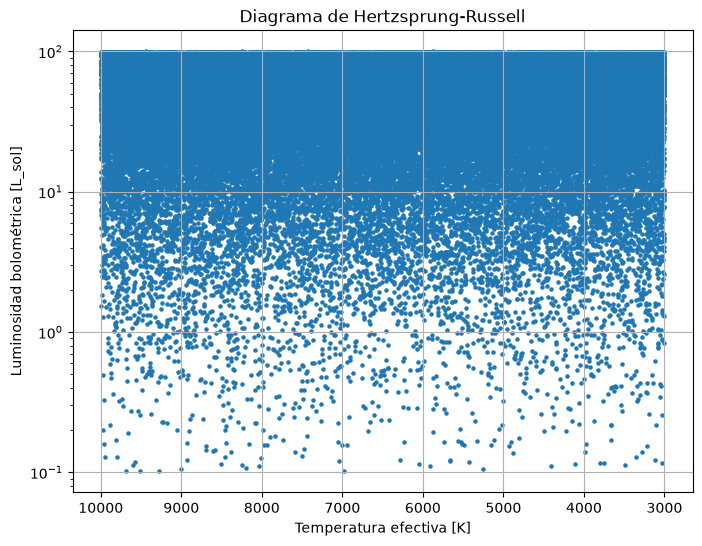

In [8]:
# Generamos el diagrama de Hertzsprung-Russell
catalogo.graficar_hr()
plt.show()

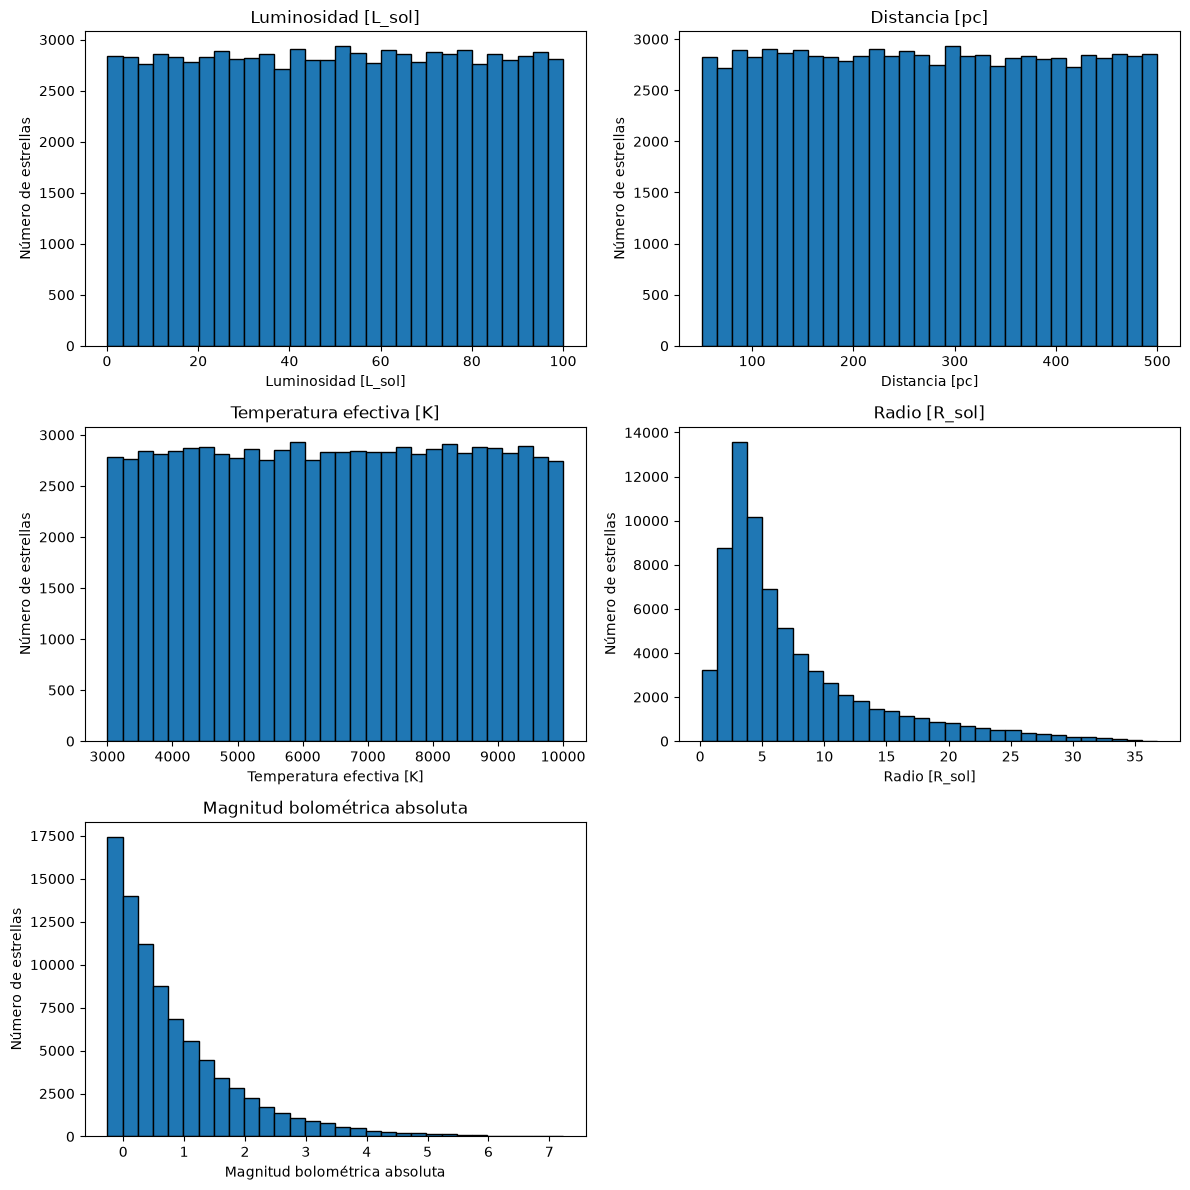

In [9]:
# Generamos los histogramas utilizando 30 intervalos
catalogo.graficar_histogramas(bins=30)
plt.show()

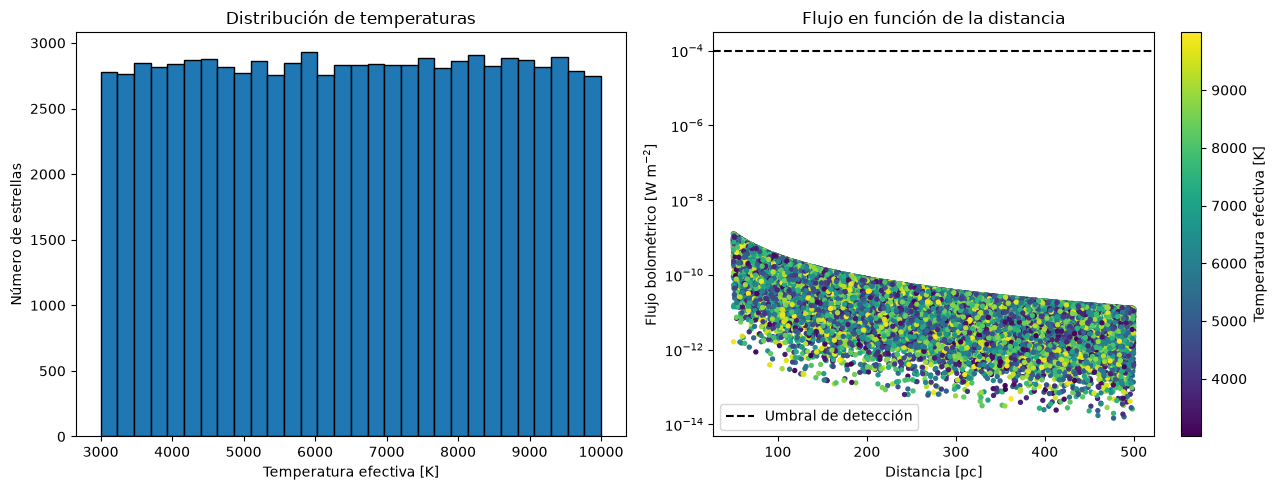

In [10]:
# Generamos los dos gráficos solicitados
catalogo.graficar_temperatura_flujo()
plt.show()

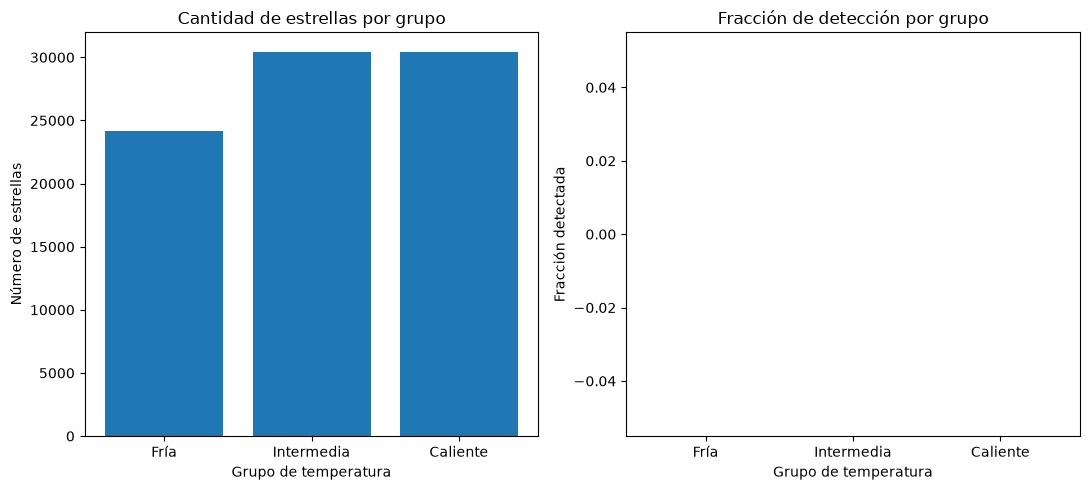

In [11]:
# Representamos la cantidad de estrellas y la fracción detectada por grupo
catalogo.graficar_grupos()
plt.show()

In [12]:
# Guardamos el catálogo procesado en formato CSV
catalogo.guardar_resultados("catalogo_procesado.csv")

Catálogo guardado en: catalogo_procesado.csv


In [13]:
# Construimos manualmente un DataFrame con diez estrellas
datos_prueba = pd.DataFrame({
    "nombre": ["Estrella 1", "Estrella 2", "Estrella 3", "Estrella 4", "Estrella 5",
               "Estrella 6", "Estrella 7", "Estrella 8", "Estrella 9", "Estrella 10"],
    "L_Lsol": [1.0, 2.0, 0.5, 4.0, 1.5, 3.0, 0.8, 5.0, 2.5, 1.2],
    "d_pc": [10.0, 20.0, 15.0, 30.0, 25.0, 40.0, 12.0, 50.0, 35.0, 18.0],
    "T_K": [4500.0, 5200.0, 3800.0, 7800.0, 6000.0, 9000.0, 4800.0, 8200.0, 7000.0, 5500.0]
})

# Creamos una instancia utilizando el método de clase
catalogo_prueba = CatalogoEstelar.desde_dataframe(datos_prueba)

# Calculamos las propiedades físicas de las estrellas de prueba
catalogo_prueba.calcular_flujo()
catalogo_prueba.calcular_radio()
catalogo_prueba.calcular_magnitud()
catalogo_prueba.calcular_lambda_max()

# Mostramos el DataFrame procesado
catalogo_prueba.datos

Valores faltantes antes de la limpieza:
        Cantidad  Porcentaje (%)
nombre         0             0.0
L_Lsol         0             0.0
d_pc           0             0.0
T_K            0             0.0
\nValores faltantes después de la limpieza:
nombre    0
L_Lsol    0
d_pc      0
T_K       0
dtype: int64


,nombre,L_Lsol,d_pc,T_K,Fbol,R_Rsol,Mbol,lambda_max_nm
0,Estrella 1,1.0,10.0,4500.0,3.199344e-10,1.645234,4.740000,643.955556
1,Estrella 2,2.0,20.0,5200.0,1.599672e-10,1.742453,3.987425,557.269231
2,Estrella 3,0.5,15.0,3800.0,7.109654e-11,1.631438,5.492575,762.578947
3,Estrella 4,4.0,30.0,7800.0,1.421931e-10,1.095200,3.234850,371.512821
4,Estrella 5,1.5,25.0,6000.0,7.678426e-11,1.133433,4.299772,482.966667
5,Estrella 6,3.0,40.0,9000.0,5.998770e-11,0.712407,3.547197,321.977778
6,Estrella 7,0.8,12.0,4800.0,1.777413e-10,1.293347,4.982275,603.708333
7,Estrella 8,5.0,50.0,8200.0,6.398689e-11,1.107924,2.992575,353.390244
8,Estrella 9,2.5,35.0,7000.0,6.529274e-11,1.075045,3.745150,413.971429
9,Estrella 10,1.2,18.0,5500.0,1.184942e-10,1.206474,4.542047,526.872727


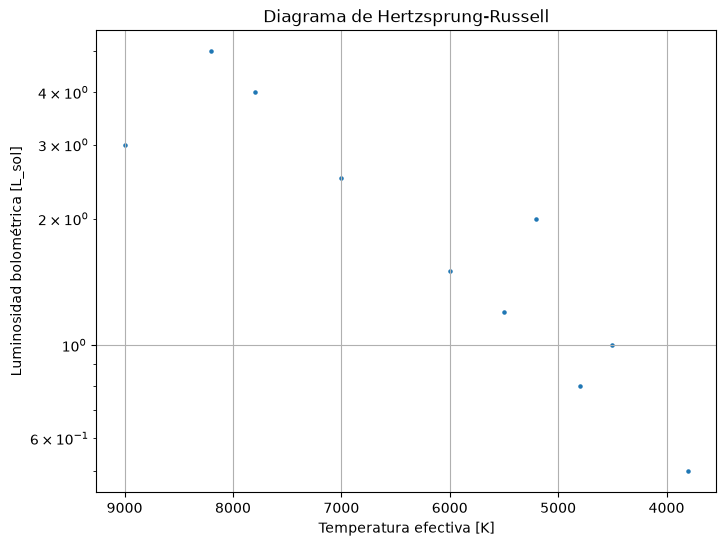

In [14]:
# Generamos una figura para comprobar que también funciona con el DataFrame
catalogo_prueba.graficar_hr()
plt.show()

In [25]:
# Contamos las estrellas detectadas con el umbral predeterminado
deteccion_1 = catalogo.clasificar_deteccion(umbral=1e-4)
n_detectadas_1 = (deteccion_1 == "Detectada").sum()

# Repetimos la clasificación con un umbral menor
deteccion_2 = catalogo.clasificar_deteccion(umbral=1e-12)
n_detectadas_2 = (deteccion_2 == "Detectada").sum()

# Mostramos y comparamos los resultados
print("Detectadas con umbral 1e-4 W/m2:", n_detectadas_1)
print("Detectadas con umbral 1e-12 W/m2:", n_detectadas_2)
print("Diferencia:", n_detectadas_2 - n_detectadas_1)

Detectadas con umbral 1e-4 W/m2: 0
Detectadas con umbral 1e-12 W/m2: 70272
Diferencia: 70272
